In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import warnings
warnings.filterwarnings('ignore')

# তোমার Path
path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'

extractors = [
    'AlexNet', 'CustomCNN', 'DenseNet121', 'EfficientNetB0', 'InceptionV3',
    'MobileNetV2', 'ResNet50', 'VGG16', 'ViT', 'Xception'
]

classifiers = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(random_state=42)
}

results = pd.DataFrame(columns=['Feature Extractor'] +
                       list(classifiers.keys()) + ['Best', 'Best Accuracy'])
results['Feature Extractor'] = extractors

print("\n🔰 Starting F1 + F2 + F4 merge processing...\n")

for extractor in extractors:
    print(f'\nProcessing {extractor} ...')

    # -------- FILES FOR F1 + F2 + F4 --------
    f1_file = f'{path}F1_Features_{extractor}.csv'
    f2_file = f'{path}F2_Features_{extractor}.csv'
    f4_file = f'{path}F4_Features_{extractor}.csv'

    df1 = pd.read_csv(f1_file)
    df2 = pd.read_csv(f2_file)
    df4 = pd.read_csv(f4_file)

    # -------- FIND LABEL COLUMN (from F1) --------
    possible_label_cols = ['label', 'class', 'target', 'phoneme',
                           'category', 'Label', 'Class', 'phoneme_label']

    label_col = None
    for col in possible_label_cols:
        if col in df1.columns:
            label_col = col
            break

    if label_col is None:
        label_col = df1.columns[1]
        print(f"   → লেবেল কলাম ধরা হলো: {label_col}")

    # -------- CLEAN UNWANTED COLUMNS --------
    def clean_features(df):
        df = df.copy()
        drop_cols = [c for c in df.columns if any(x in c.lower()
                                                  for x in ['filename','path','unnamed','index'])]
        df.drop(columns=drop_cols, errors='ignore', inplace=True)
        return df

    df1_clean = clean_features(df1)
    df2_clean = clean_features(df2)
    df4_clean = clean_features(df4)

    # Separate features + label (label from F1)
    X1 = df1_clean.drop(columns=[label_col], errors='ignore')
    X2 = df2_clean.drop(columns=[label_col], errors='ignore')
    X4 = df4_clean.drop(columns=[label_col], errors='ignore')

    y = df1_clean[label_col]

    # ---------------- MERGE F1 + F2 + F4 ----------------
    X = pd.concat([
        X1.reset_index(drop=True),
        X2.reset_index(drop=True),
        X4.reset_index(drop=True)
    ], axis=1)

    # -------- SAFETY CHECK: Only 1 class --------
    if len(y.unique()) == 1:
        print(f"   ❌ Skipped {extractor}: Only 1 class → {y.unique()[0]}")
        for name in classifiers.keys():
            results.loc[results['Feature Extractor'] == extractor, name] = "NA"
        results.loc[results['Feature Extractor'] == extractor, 'Best'] = "NA"
        results.loc[results['Feature Extractor'] == extractor, 'Best Accuracy'] = "NA"
        continue

    # -------- TRAIN/TEST SPLIT --------
    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y
        )
    except ValueError:
        print(f"   → Stratify সমস্যা: stratify ছাড়া split করা হলো")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42
        )

    best_acc = 0
    best_name = ''

    # -------- RUN ALL CLASSIFIERS --------
    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        acc = round(accuracy_score(y_test, y_pred), 4)

        results.loc[results['Feature Extractor'] == extractor, name] = acc

        if acc > best_acc:
            best_acc = acc
            best_name = name

    results.loc[results['Feature Extractor'] == extractor, 'Best'] = best_name
    results.loc[results['Feature Extractor'] == extractor, 'Best Accuracy'] = best_acc

# -------- SAVE EXCEL --------
output_file = path + 'Summary_F1_F2_F4.xlsx'
results.to_excel(output_file, index=False)

print("\n✅ DONE! তোমার F1+F2+F4 Summary Excel তৈরি হয়েছে:")
print(output_file)
display(results)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🔰 Starting F1 + F2 + F4 merge processing...


Processing AlexNet ...

Processing CustomCNN ...

Processing DenseNet121 ...

Processing EfficientNetB0 ...

Processing InceptionV3 ...

Processing MobileNetV2 ...

Processing ResNet50 ...

Processing VGG16 ...

Processing ViT ...

Processing Xception ...

✅ DONE! তোমার F1+F2+F4 Summary Excel তৈরি হয়েছে:
/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/Summary_F1_F2_F4.xlsx


,Feature Extractor,AdaBoost,Decision Tree,Extra Trees,Gradient Boosting,KNN,Logistic Regression,Naive Bayes,Random Forest,SVM,Best,Best Accuracy
0,AlexNet,0.9048,0.8286,0.8952,0.9048,0.8857,0.9238,0.8095,0.8762,0.9048,Logistic Regression,0.9238
1,CustomCNN,0.8762,0.7714,0.8286,0.8762,0.781,0.9238,0.6571,0.8571,0.8762,Logistic Regression,0.9238
2,DenseNet121,0.9238,0.8381,0.8857,0.8762,0.8667,0.9238,0.8952,0.8857,0.9143,AdaBoost,0.9238
3,EfficientNetB0,0.8857,0.8667,0.8762,0.8857,0.8667,0.9143,0.9048,0.9048,0.9143,Logistic Regression,0.9143
4,InceptionV3,0.8667,0.8571,0.8571,0.8762,0.8857,0.9429,0.8762,0.8476,0.8952,Logistic Regression,0.9429
5,MobileNetV2,0.9048,0.9143,0.8952,0.8952,0.9048,0.9238,0.8857,0.8952,0.9333,SVM,0.9333
6,ResNet50,0.9143,0.8667,0.8857,0.9048,0.9238,0.9048,0.8952,0.8762,0.9238,KNN,0.9238
7,VGG16,0.9143,0.8667,0.8952,0.8857,0.8857,0.9333,0.7905,0.8952,0.9238,Logistic Regression,0.9333
8,ViT,0.8667,0.7524,0.8381,0.819,0.8476,0.8762,0.8667,0.8571,0.8571,Logistic Regression,0.8762
9,Xception,0.9333,0.8286,0.8857,0.8952,0.819,0.9238,0.8762,0.8952,0.8952,AdaBoost,0.9333


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Final feature shape (F1+F2+F4): (523, 6144)

Confusion Matrix (InceptionV3 + Logistic Regression):
[[36  3]
 [ 3 63]]


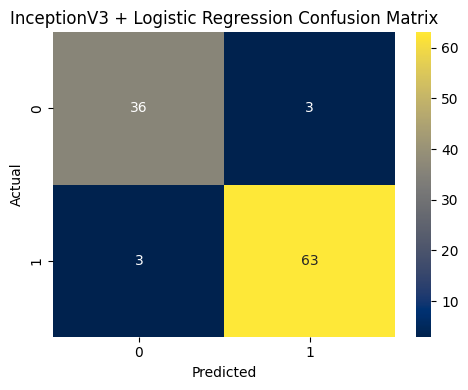


Performance Table:


,Metric,Value (%)
0,Accuracy,94.29
1,Precision,95.45
2,Recall,95.45
3,F1-score,95.45



✅ Saved Files:
- Confusion Matrix Image: F1_F2_F4_InceptionV3_Confusion_Matrix.png
- Performance Table Excel: F1_F2_F4_InceptionV3_Performance.xlsx


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')

# ================= PATH =================
csv_path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'
save_path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/Feature_Extract/'

os.makedirs(save_path, exist_ok=True)

# ================= BEST MODEL INFO =================
extractor = 'InceptionV3'
model_name = 'Logistic Regression'
model = LogisticRegression(max_iter=2000, random_state=42)

# ================= LOAD & MERGE F1 + F2 + F4 =================
f1 = pd.read_csv(f'{csv_path}F1_Features_{extractor}.csv')
f2 = pd.read_csv(f'{csv_path}F2_Features_{extractor}.csv')
f4 = pd.read_csv(f'{csv_path}F4_Features_{extractor}.csv')

# Detect label
label_col = None
for col in ['label', 'Label', 'class', 'Class']:
    if col in f1.columns:
        label_col = col
        break

y = f1[label_col]

def clean(df):
    drop_cols = [c for c in df.columns if any(x in c.lower()
                 for x in ['label','filename','path','unnamed','index'])]
    return df.drop(columns=drop_cols, errors='ignore')

X = pd.concat([
    clean(f1),
    clean(f2),
    clean(f4)
], axis=1)

print("Final feature shape (F1+F2+F4):", X.shape)

# ================= TRAIN / TEST =================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_test, y_pred)
print(f"\nConfusion Matrix ({extractor} + {model_name}):\n{cm}")

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='cividis')
plt.title(f'{extractor} + {model_name} Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(f'{save_path}F1_F2_F4_{extractor}_Confusion_Matrix.png')
plt.show()

# ================= PERFORMANCE TABLE =================
perf_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value (%)': [
        round(accuracy_score(y_test, y_pred)*100, 2),
        round(precision_score(y_test, y_pred)*100, 2),
        round(recall_score(y_test, y_pred)*100, 2),
        round(f1_score(y_test, y_pred)*100, 2)
    ]
})

print("\nPerformance Table:")
display(perf_table)

# Save table
perf_table.to_excel(
    f'{save_path}F1_F2_F4_{extractor}_Performance.xlsx',
    index=False
)

print("\n✅ Saved Files:")
print(f"- Confusion Matrix Image: F1_F2_F4_{extractor}_Confusion_Matrix.png")
print(f"- Performance Table Excel: F1_F2_F4_{extractor}_Performance.xlsx")
